In [79]:
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Load Dataset


In [80]:
df=pd.read_csv(r'C:\Users\asd\Desktop\AI\Smart Assistant _Graduation project_ITI\aug_train.csv')

# Understand Dataset

In [81]:
display(df.shape)

(19158, 14)

In [82]:
display(df.head(5))


,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,NaN,NaN,1,36,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0.0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5,NaN,NaN,never,83,0.0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,<1,NaN,Pvt Ltd,never,52,1.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,>20,50-99,Funded Startup,4,8,0.0


In [83]:
display(df.columns)


Index(['enrollee_id', 'city', 'city_development_index', 'gender',
       'relevent_experience', 'enrolled_university', 'education_level',
       'major_discipline', 'experience', 'company_size', 'company_type',
       'last_new_job', 'training_hours', 'target'],
      dtype='object')

In [84]:
display(df.describe())
print('=='*50)

,enrollee_id,city_development_index,training_hours,target
count,19158.000000,19158.000000,19158.000000,19158.000000
mean,16875.358179,0.828848,65.366896,0.249348
std,9616.292592,0.123362,60.058462,0.432647
min,1.000000,0.448000,1.000000,0.000000
25%,8554.250000,0.740000,23.000000,0.000000
50%,16982.500000,0.903000,47.000000,0.000000
75%,25169.750000,0.920000,88.000000,0.000000
max,33380.000000,0.949000,336.000000,1.000000


In [85]:
display(df.info())
print('=='*50)    

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19158 entries, 0 to 19157
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   enrollee_id             19158 non-null  int64  
 1   city                    19158 non-null  object 
 2   city_development_index  19158 non-null  float64
 3   gender                  14650 non-null  object 
 4   relevent_experience     19158 non-null  object 
 5   enrolled_university     18772 non-null  object 
 6   education_level         18698 non-null  object 
 7   major_discipline        16345 non-null  object 
 8   experience              19093 non-null  object 
 9   company_size            13220 non-null  object 
 10  company_type            13018 non-null  object 
 11  last_new_job            18735 non-null  object 
 12  training_hours          19158 non-null  int64  
 13  target                  19158 non-null  float64
dtypes: float64(2), int64(2), object(10)
me

None

# Cleaning

In [86]:
df.isnull().sum()

enrollee_id                  0
city                         0
city_development_index       0
gender                    4508
relevent_experience          0
enrolled_university        386
education_level            460
major_discipline          2813
experience                  65
company_size              5938
company_type              6140
last_new_job               423
training_hours               0
target                       0
dtype: int64

In [87]:
null_percentage = df.isnull().mean() * 100

null_percentage.sort_values(ascending=False)

company_type              32.049274
company_size              30.994885
gender                    23.530640
major_discipline          14.683161
education_level            2.401086
last_new_job               2.207955
enrolled_university        2.014824
experience                 0.339284
enrollee_id                0.000000
city                       0.000000
relevent_experience        0.000000
city_development_index     0.000000
training_hours             0.000000
target                     0.000000
dtype: float64

In [88]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19158 entries, 0 to 19157
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   enrollee_id             19158 non-null  int64  
 1   city                    19158 non-null  object 
 2   city_development_index  19158 non-null  float64
 3   gender                  14650 non-null  object 
 4   relevent_experience     19158 non-null  object 
 5   enrolled_university     18772 non-null  object 
 6   education_level         18698 non-null  object 
 7   major_discipline        16345 non-null  object 
 8   experience              19093 non-null  object 
 9   company_size            13220 non-null  object 
 10  company_type            13018 non-null  object 
 11  last_new_job            18735 non-null  object 
 12  training_hours          19158 non-null  int64  
 13  target                  19158 non-null  float64
dtypes: float64(2), int64(2), object(10)
me

In [89]:
categorical_unknown = ['company_type','company_size','gender', 'major_discipline']

categorical_mode = ['education_level', 'last_new_job', 'enrolled_university']

for un in categorical_unknown:
    df[un]=df[un].fillna('Unknown')

for mod in  categorical_mode:
    df[mod] = df[mod].fillna(df[mod].mode()[0])


In [90]:
df['experience'].value_counts(dropna=False)

experience
>20    3286
5      1430
4      1403
3      1354
6      1216
2      1127
7      1028
10      985
9       980
8       802
15      686
11      664
14      586
1       549
<1      522
16      508
12      494
13      399
17      342
19      304
18      280
20      148
NaN      65
Name: count, dtype: int64

In [91]:
df['experience'] = df['experience'].replace({
    '<1': 1,
    '>20': 20
})

df['experience'] = pd.to_numeric(
    df['experience'],
    errors='coerce'
)

In [92]:
df['experience'].value_counts(dropna=False)

experience
20.0    3434
5.0     1430
4.0     1403
3.0     1354
6.0     1216
2.0     1127
1.0     1071
7.0     1028
10.0     985
9.0      980
8.0      802
15.0     686
11.0     664
14.0     586
16.0     508
12.0     494
13.0     399
17.0     342
19.0     304
18.0     280
NaN       65
Name: count, dtype: int64

In [93]:
df['experience'].mean()

np.float64(9.955376315927303)

In [94]:
experience_mean = df['experience'].mean()

df['experience'] = df['experience'].fillna(experience_mean)

In [95]:
df.isnull().sum()

enrollee_id               0
city                      0
city_development_index    0
gender                    0
relevent_experience       0
enrolled_university       0
education_level           0
major_discipline          0
experience                0
company_size              0
company_type              0
last_new_job              0
training_hours            0
target                    0
dtype: int64

In [96]:
columns=['gender',
       'relevent_experience', 'enrolled_university', 'education_level',
       'major_discipline', 'experience', 'company_size', 'company_type',
       'last_new_job', 'training_hours', 'target']
for col in columns:
   print(f'{col} : {df[col].unique()}')

gender : ['Male' 'Unknown' 'Female' 'Other']
relevent_experience : ['Has relevent experience' 'No relevent experience']
enrolled_university : ['no_enrollment' 'Full time course' 'Part time course']
education_level : ['Graduate' 'Masters' 'High School' 'Phd' 'Primary School']
major_discipline : ['STEM' 'Business Degree' 'Unknown' 'Arts' 'Humanities' 'No Major' 'Other']
experience : [20.         15.          5.          1.         11.         13.
  7.         17.          2.         16.          4.         10.
 14.         18.         19.         12.          3.          6.
  9.          8.          9.95537632]
company_size : ['Unknown' '50-99' '<10' '10000+' '5000-9999' '1000-4999' '10/49'
 '100-500' '500-999']
company_type : ['Unknown' 'Pvt Ltd' 'Funded Startup' 'Early Stage Startup' 'Other'
 'Public Sector' 'NGO']
last_new_job : ['1' '>4' 'never' '4' '3' '2']
training_hours : [ 36  47  83  52   8  24  18  46 123  32 108  23  26 106   7 132  68  50
  48  65  13  22 148  72  40 141  82 

In [97]:
df['relevent_experience'] =df['relevent_experience'].replace({
'Has relevent experience':1,
'No relevent experience':0
})   

df['last_new_job'] = df['last_new_job'].replace({
    'never': 0,
    '1': 1,
    '2': 2,
    '3': 3,
    '4': 4,
    '>4': 5
})



C:\Users\asd\AppData\Local\Temp\ipykernel_33424\714782809.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['relevent_experience'] =df['relevent_experience'].replace({
C:\Users\asd\AppData\Local\Temp\ipykernel_33424\714782809.py:6: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['last_new_job'] = df['last_new_job'].replace({


In [98]:
df.duplicated().sum()

np.int64(0)

In [99]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19158 entries, 0 to 19157
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   enrollee_id             19158 non-null  int64  
 1   city                    19158 non-null  object 
 2   city_development_index  19158 non-null  float64
 3   gender                  19158 non-null  object 
 4   relevent_experience     19158 non-null  int64  
 5   enrolled_university     19158 non-null  object 
 6   education_level         19158 non-null  object 
 7   major_discipline        19158 non-null  object 
 8   experience              19158 non-null  float64
 9   company_size            19158 non-null  object 
 10  company_type            19158 non-null  object 
 11  last_new_job            19158 non-null  int64  
 12  training_hours          19158 non-null  int64  
 13  target                  19158 non-null  float64
dtypes: float64(3), int64(4), object(7)
mem

In [100]:
df['relevent_experience'] = df['relevent_experience'].astype(int)
df['last_new_job'] = df['last_new_job'].astype(int)
df['target'] = df['target'].astype(int)
df['experience'] = df['experience'].astype(int)

In [101]:
df['target'].value_counts(normalize=True) * 100

target
0    75.065247
1    24.934753
Name: proportion, dtype: float64

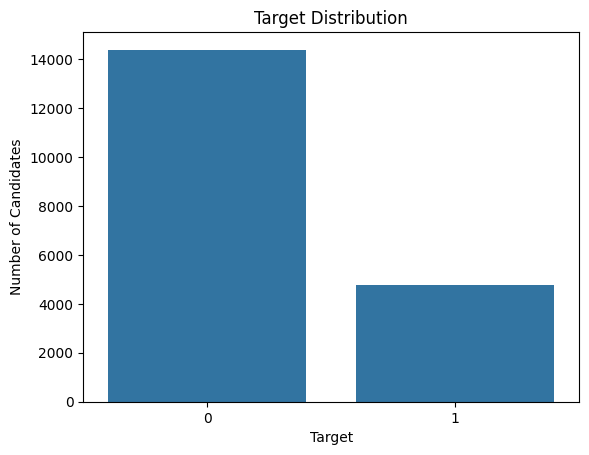

In [102]:


sns.countplot(x='target', data=df)

plt.title('Target Distribution')
plt.xlabel('Target')
plt.ylabel('Number of Candidates')
plt.show()

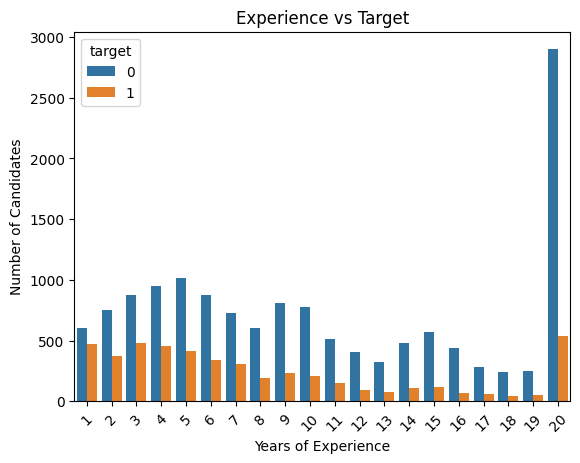

In [103]:
sns.countplot(
    x='experience',
    hue='target',
    data=df
)

plt.title('Experience vs Target')
plt.xlabel('Years of Experience')
plt.ylabel('Number of Candidates')
plt.xticks(rotation=45)
plt.show()

# EDA

In [104]:
numerical_cols = [
    'city_development_index',
    'experience',
    'last_new_job',
    'training_hours'
]

df[numerical_cols].describe()

,city_development_index,experience,last_new_job,training_hours
count,19158.000000,19158.000000,19158.000000,19158.000000
mean,0.828848,9.952135,1.978338,65.366896
std,0.123362,6.454725,1.663502,60.058462
min,0.448000,1.000000,0.000000,1.000000
25%,0.740000,4.000000,1.000000,23.000000
50%,0.903000,9.000000,1.000000,47.000000
75%,0.920000,16.000000,3.000000,88.000000
max,0.949000,20.000000,5.000000,336.000000


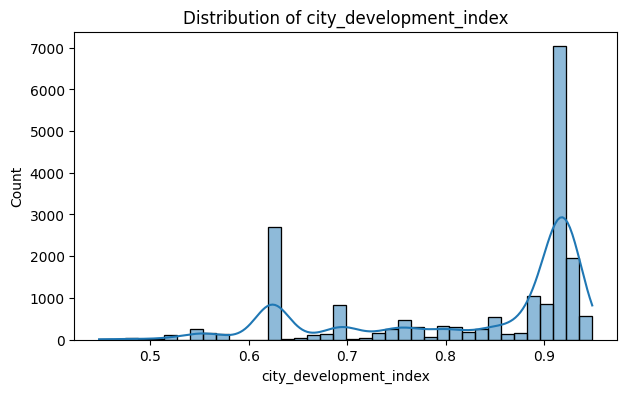

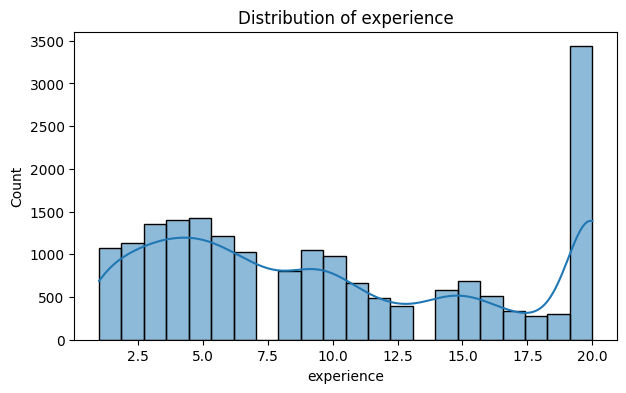

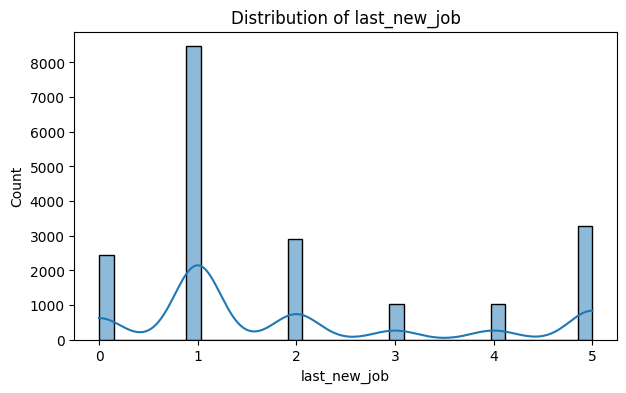

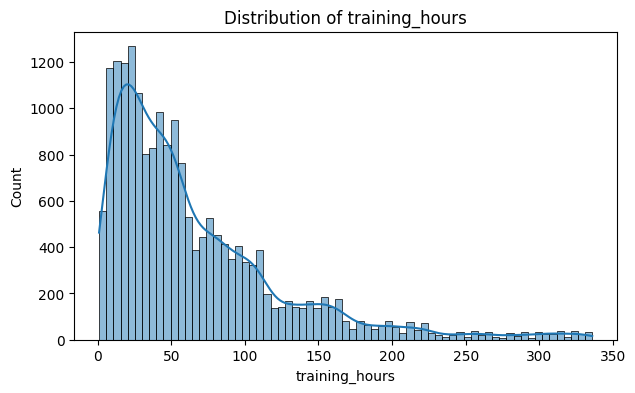

In [105]:
for col in numerical_cols:
    plt.figure(figsize=(7, 4))
    sns.histplot(data=df, x=col, kde=True)
    plt.title(f'Distribution of {col}')
    plt.show()

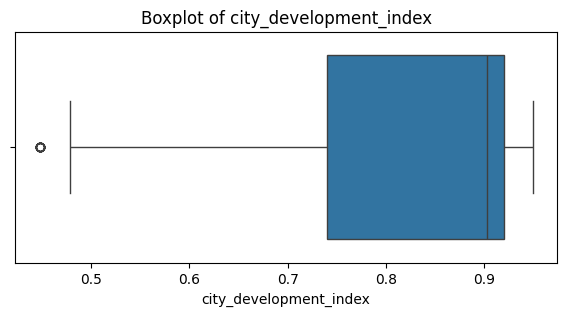

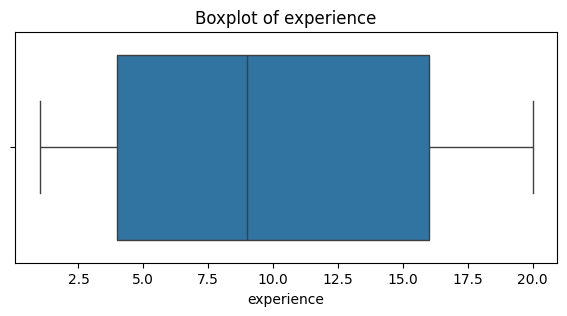

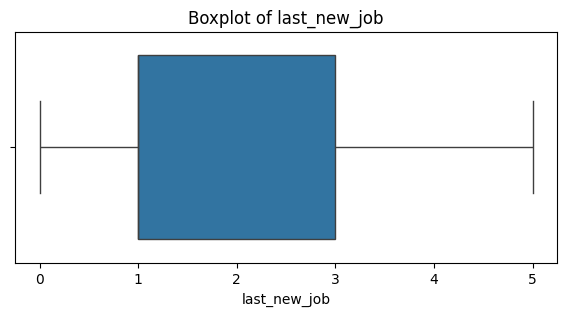

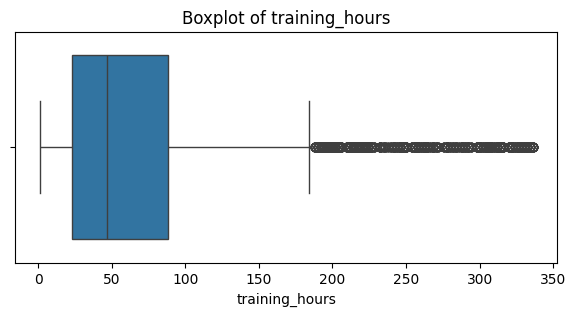

In [106]:
for col in numerical_cols:
    plt.figure(figsize=(7, 3))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
    plt.show()

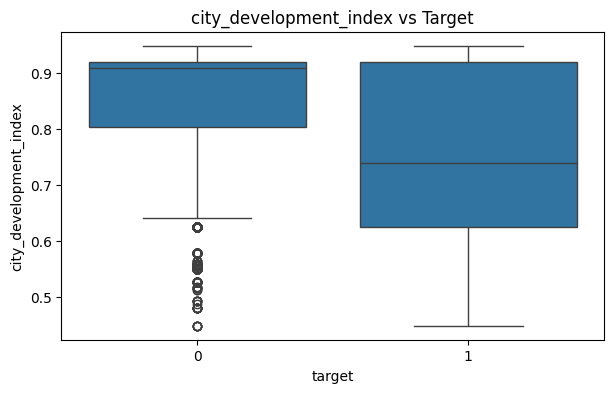

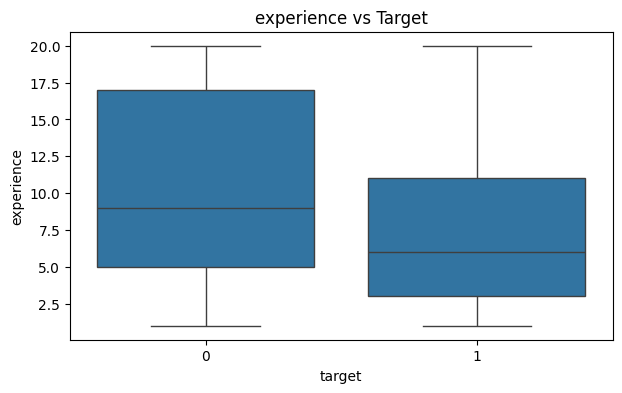

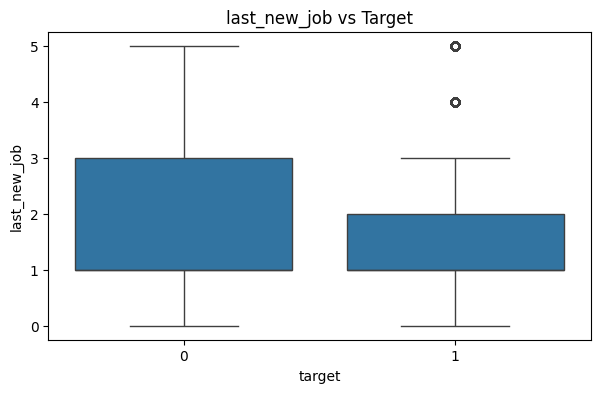

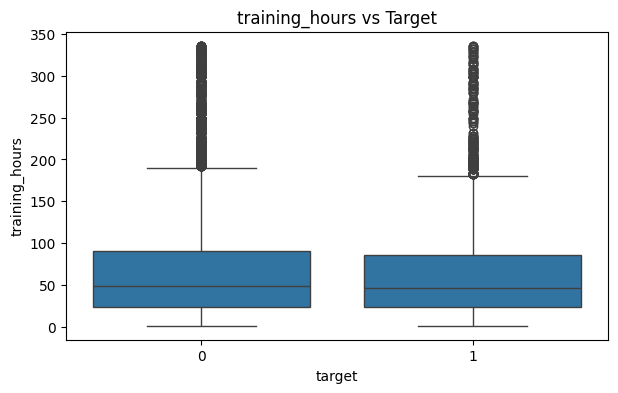

In [107]:
for col in numerical_cols:
    plt.figure(figsize=(7, 4))
    sns.boxplot(x='target', y=col, data=df)
    plt.title(f'{col} vs Target')
    plt.show()

In [108]:
categorical_cols = [
    'gender',
    'enrolled_university',
    'education_level',
    'major_discipline',
    'company_size',
    'company_type'
]

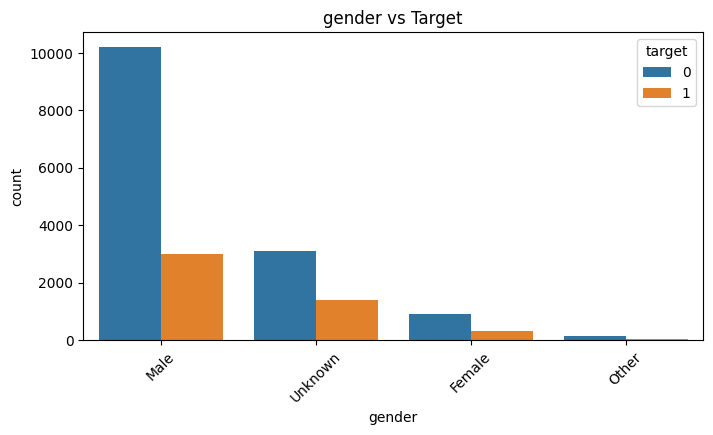

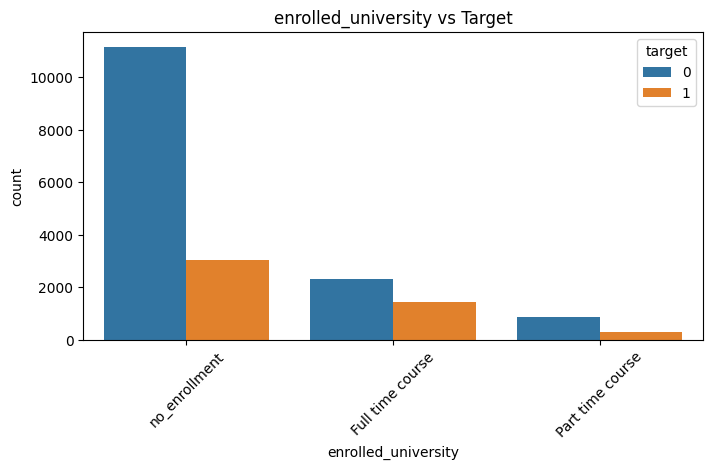

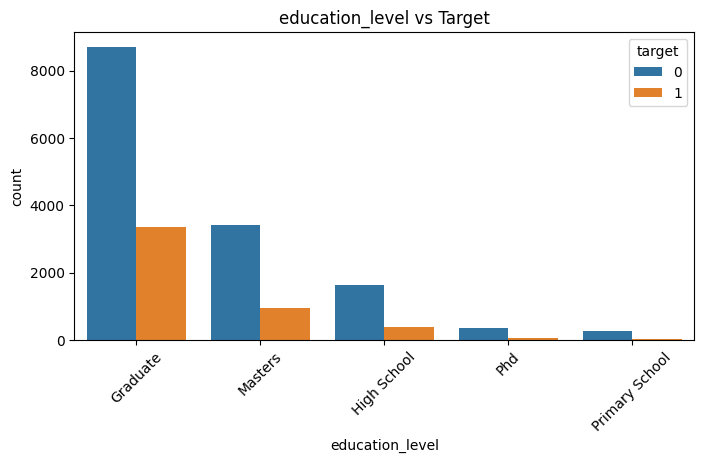

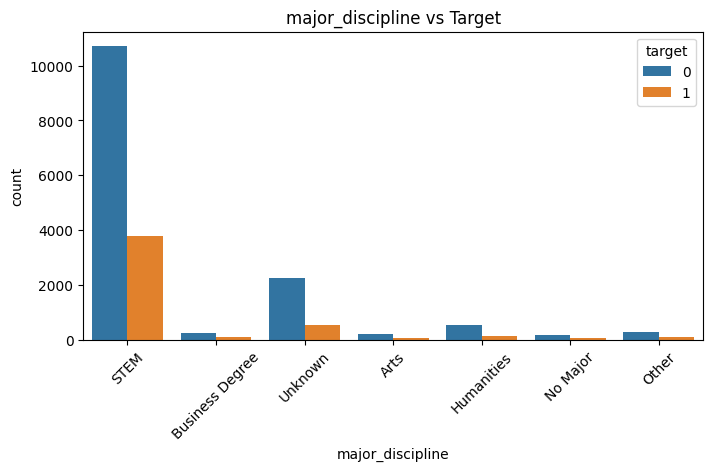

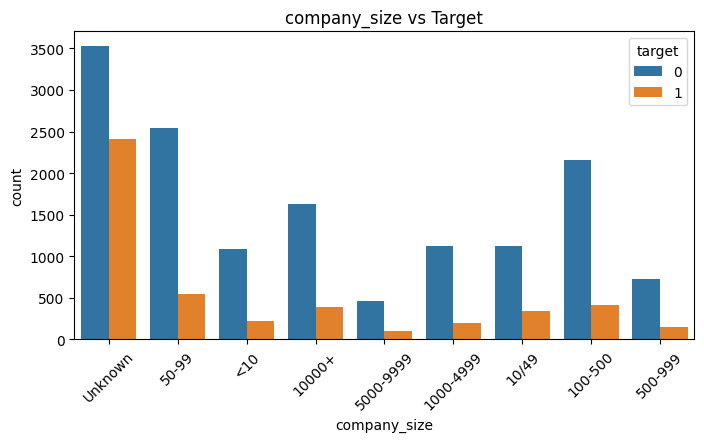

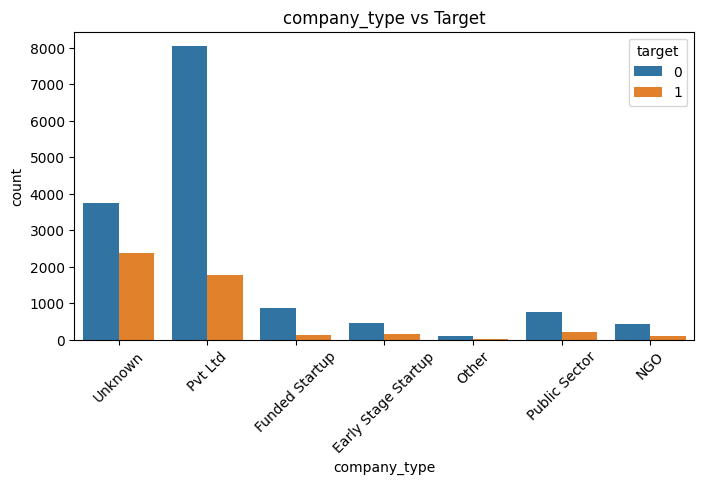

In [109]:
for col in categorical_cols:
    plt.figure(figsize=(8, 4))
    sns.countplot(data=df, x=col, hue='target')
    plt.title(f'{col} vs Target')
    plt.xticks(rotation=45)
    plt.show()

In [110]:
for col in categorical_cols:
    result = pd.crosstab(
        df[col],
        df['target'],
        normalize='index'
    ) * 100
    
    print(f'\n{col}')
    display(result.round(2))
    print('=='*50)


gender


target,0,1
gender,,
Female,73.67,26.33
Male,77.22,22.78
Other,73.82,26.18
Unknown,69.19,30.81



enrolled_university


target,0,1
enrolled_university,,
Full time course,61.91,38.09
Part time course,74.79,25.21
no_enrollment,78.57,21.43



education_level


target,0,1
education_level,,
Graduate,72.23,27.77
High School,80.47,19.53
Masters,78.56,21.44
Phd,85.99,14.01
Primary School,86.69,13.31



major_discipline


target,0,1
major_discipline,,
Arts,79.05,20.95
Business Degree,73.70,26.30
Humanities,78.92,21.08
No Major,75.34,24.66
Other,73.23,26.77
STEM,73.84,26.16
Unknown,80.48,19.52



company_size


target,0,1
company_size,,
10/49,76.61,23.39
100-500,83.86,16.14
1000-4999,84.94,15.06
10000+,80.93,19.07
50-99,82.32,17.68
500-999,82.67,17.33
5000-9999,81.88,18.12
<10,82.87,17.13
Unknown,59.41,40.59



company_type


target,0,1
company_type,,
Early Stage Startup,76.45,23.55
Funded Startup,86.01,13.99
NGO,81.38,18.62
Other,76.03,23.97
Public Sector,78.01,21.99
Pvt Ltd,81.92,18.08
Unknown,61.17,38.83


In [111]:
df = df.drop('enrollee_id', axis=1)

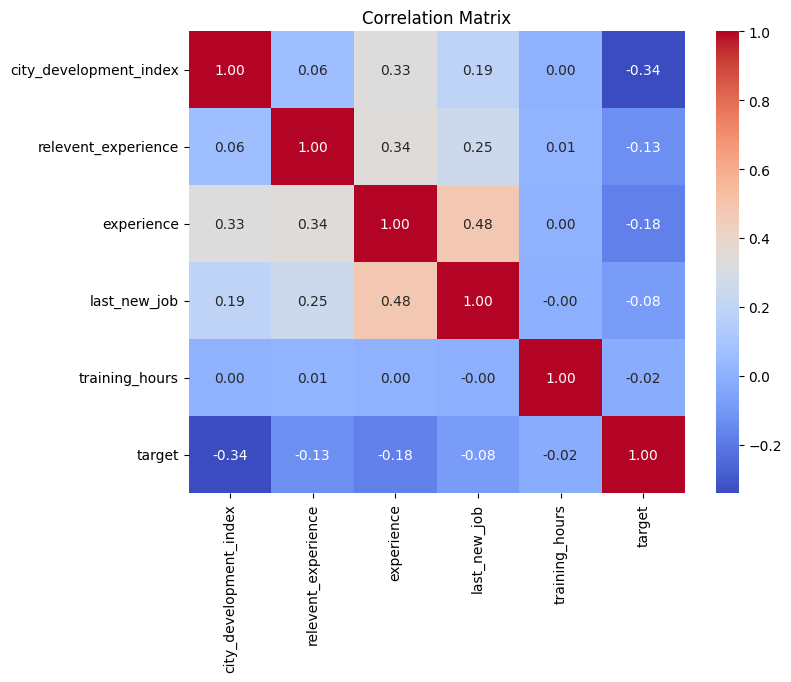

In [112]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Matrix')
plt.show()

# Feature Engineering

In [113]:
df['experience_level'] = pd.cut(
    df['experience'],
    bins=[0, 2, 5, 10, 20],
    labels=['Entry', 'Junior', 'Mid', 'Senior'],
    include_lowest=True
)

In [114]:
df['development_level'] = pd.cut(
    df['city_development_index'],
    bins=[0, 0.6, 0.8, 0.9, 1],
    labels=['Low', 'Medium', 'High', 'Very High'],
    include_lowest=True
)

In [115]:
missing_cols = [
    'gender',
    'major_discipline',
    'company_size',
    'company_type'
]

for col in missing_cols:
    df[col + '_missing'] = (
        df[col] == 'Unknown'
    ).astype(int)

In [116]:
df['high_training'] = (
    df['training_hours'] >= 100
).astype(int)

In [117]:
X = df.drop('target', axis=1)
y = df['target']

In [118]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [119]:
numerical_features = [
    'city_development_index',
    'experience',
    'last_new_job',
    'training_hours',
    'relevent_experience'
]

categorical_features = [
    'city',
    'gender',
    'enrolled_university',
    'education_level',
    'major_discipline',
    'company_size',
    'company_type'
]

In [120]:
print(X.shape)
print(y.shape)

print(X.head())
print(y.head())

(19158, 19)
(19158,)
       city  city_development_index   gender  relevent_experience  \
0  city_103                   0.920     Male                    1   
1   city_40                   0.776     Male                    0   
2   city_21                   0.624  Unknown                    0   
3  city_115                   0.789  Unknown                    0   
4  city_162                   0.767     Male                    1   

  enrolled_university education_level major_discipline  experience  \
0       no_enrollment        Graduate             STEM          20   
1       no_enrollment        Graduate             STEM          15   
2    Full time course        Graduate             STEM           5   
3       no_enrollment        Graduate  Business Degree           1   
4       no_enrollment         Masters             STEM          20   

  company_size    company_type  last_new_job  training_hours experience_level  \
0      Unknown         Unknown             1              36  

In [121]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

In [122]:
print(X.shape)
print(y.shape)

(19158, 19)
(19158,)


In [123]:
X_train_processed = preprocessor.fit_transform(X_train)

X_val_processed = preprocessor.transform(X_val)

In [124]:
logistic_model = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_processed, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default 

In [125]:
y_pred_logistic = logistic_model.predict(X_val_processed)

In [126]:
print("Accuracy :", accuracy_score(y_val, y_pred_logistic))
print("Precision:", precision_score(y_val, y_pred_logistic))
print("Recall   :", recall_score(y_val, y_pred_logistic))
print("F1 Score :", f1_score(y_val, y_pred_logistic))

print("\nClassification Report:")
print(classification_report(y_val, y_pred_logistic))

Accuracy : 0.7713987473903967
Precision: 0.5279151943462898
Recall   : 0.7821989528795812
F1 Score : 0.6303797468354431

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.77      0.83      2877
           1       0.53      0.78      0.63       955

    accuracy                           0.77      3832
   macro avg       0.72      0.78      0.73      3832
weighted avg       0.82      0.77      0.78      3832



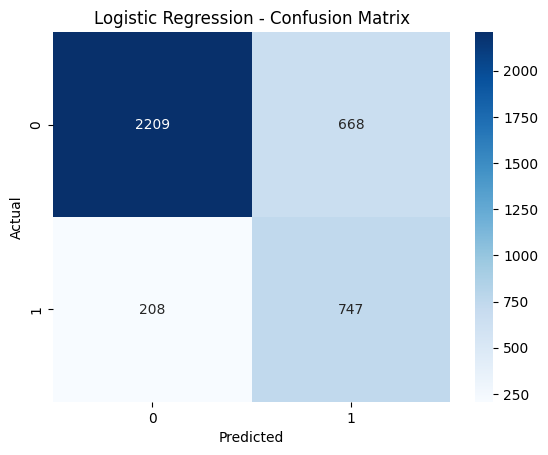

In [127]:
cm = confusion_matrix(y_val, y_pred_logistic)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Logistic Regression - Confusion Matrix')
plt.show()

In [128]:
rf_model = RandomForestClassifier(
    n_estimators=50,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

y_pred_rf = rf_model.predict(X_val_processed)

In [129]:
print("Accuracy :", accuracy_score(y_val, y_pred_rf))
print("Precision:", precision_score(y_val, y_pred_rf))
print("Recall   :", recall_score(y_val, y_pred_rf))
print("F1 Score :", f1_score(y_val, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_val, y_pred_rf))

Accuracy : 0.7857515657620042
Precision: 0.5607985480943739
Recall   : 0.6471204188481675
F1 Score : 0.6008750607681089

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.83      0.85      2877
           1       0.56      0.65      0.60       955

    accuracy                           0.79      3832
   macro avg       0.72      0.74      0.73      3832
weighted avg       0.80      0.79      0.79      3832



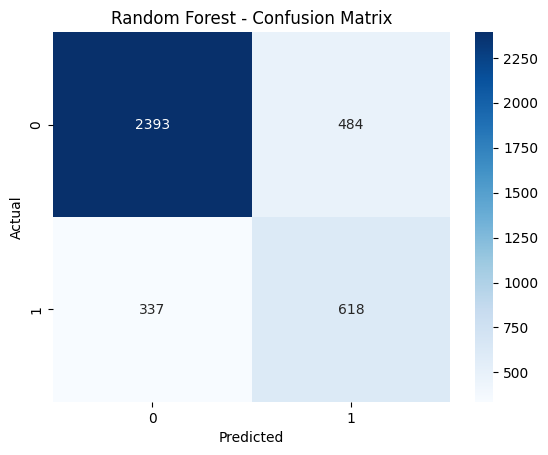

In [130]:
cm = confusion_matrix(y_val, y_pred_rf)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Random Forest - Confusion Matrix')
plt.show()

In [131]:
xgb_model = XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train_processed, y_train)

y_pred_xgb = xgb_model.predict(X_val_processed)
print("Accuracy :", accuracy_score(y_val, y_pred_xgb))
print("Precision:", precision_score(y_val, y_pred_xgb))
print("Recall   :", recall_score(y_val, y_pred_xgb))
print("F1 Score :", f1_score(y_val, y_pred_xgb))

print("\nClassification Report:")
print(classification_report(y_val, y_pred_xgb))

Accuracy : 0.7961899791231732
Precision: 0.5949781659388647
Recall   : 0.5706806282722513
F1 Score : 0.5825761624799572

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.87      0.87      2877
           1       0.59      0.57      0.58       955

    accuracy                           0.80      3832
   macro avg       0.73      0.72      0.72      3832
weighted avg       0.79      0.80      0.79      3832



In [132]:
gb_model = GradientBoostingClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    random_state=42
)

gb_model.fit(X_train_processed, y_train)

y_pred_gb = gb_model.predict(X_val_processed)

print("Accuracy :", accuracy_score(y_val, y_pred_gb))
print("Precision:", precision_score(y_val, y_pred_gb))
print("Recall   :", recall_score(y_val, y_pred_gb))
print("F1 Score :", f1_score(y_val, y_pred_gb))

Accuracy : 0.7974947807933194
Precision: 0.5903128153380424
Recall   : 0.612565445026178
F1 Score : 0.6012332990750257


In [133]:
results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest',
        'XGBoost',
        'Gradient Boosting'
    ],
    'Accuracy': [
        accuracy_score(y_val, y_pred_logistic),
        accuracy_score(y_val, y_pred_rf),
        accuracy_score(y_val, y_pred_xgb),
        accuracy_score(y_val, y_pred_gb)
    ],
    'Precision': [
        precision_score(y_val, y_pred_logistic),
        precision_score(y_val, y_pred_rf),
        precision_score(y_val, y_pred_xgb),
        precision_score(y_val, y_pred_gb)
    ],
    'Recall': [
        recall_score(y_val, y_pred_logistic),
        recall_score(y_val, y_pred_rf),
        recall_score(y_val, y_pred_xgb),
        recall_score(y_val, y_pred_gb)
    ],
    'F1': [
        f1_score(y_val, y_pred_logistic),
        f1_score(y_val, y_pred_rf),
        f1_score(y_val, y_pred_xgb),
        f1_score(y_val, y_pred_gb)
    ]
})

results.sort_values('Accuracy', ascending=False)

,Model,Accuracy,Precision,Recall,F1
3,Gradient Boosting,0.797495,0.590313,0.612565,0.601233
2,XGBoost,0.796190,0.594978,0.570681,0.582576
1,Random Forest,0.785752,0.560799,0.647120,0.600875
0,Logistic Regression,0.771399,0.527915,0.782199,0.630380


In [134]:
# Best model according to each evaluation metric

best_accuracy = results.loc[results['Accuracy'].idxmax()]
best_precision = results.loc[results['Precision'].idxmax()]
best_recall = results.loc[results['Recall'].idxmax()]
best_f1 = results.loc[results['F1'].idxmax()]

print("Best Model by Accuracy:")
print(best_accuracy[['Model', 'Accuracy']])

print("\nBest Model by Precision:")
print(best_precision[['Model', 'Precision']])

print("\nBest Model by Recall:")
print(best_recall[['Model', 'Recall']])

print("\nBest Model by F1 Score:")
print(best_f1[['Model', 'F1']])

Best Model by Accuracy:
Model       Gradient Boosting
Accuracy             0.797495
Name: 3, dtype: object

Best Model by Precision:
Model         XGBoost
Precision    0.594978
Name: 2, dtype: object

Best Model by Recall:
Model     Logistic Regression
Recall               0.782199
Name: 0, dtype: object

Best Model by F1 Score:
Model    Logistic Regression
F1                   0.63038
Name: 0, dtype: object


In [135]:
final_model = gb_model

In [136]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

y_pred_final = final_model.predict(X_val_processed)

print("Final Model Performance")
print("-----------------------")

print("Accuracy :", accuracy_score(y_val, y_pred_final))
print("Precision:", precision_score(y_val, y_pred_final))
print("Recall   :", recall_score(y_val, y_pred_final))
print("F1 Score :", f1_score(y_val, y_pred_final))

print("\nClassification Report:")
print(classification_report(y_val, y_pred_final))

Final Model Performance
-----------------------
Accuracy : 0.7974947807933194
Precision: 0.5903128153380424
Recall   : 0.612565445026178
F1 Score : 0.6012332990750257

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.86      0.86      2877
           1       0.59      0.61      0.60       955

    accuracy                           0.80      3832
   macro avg       0.73      0.74      0.73      3832
weighted avg       0.80      0.80      0.80      3832



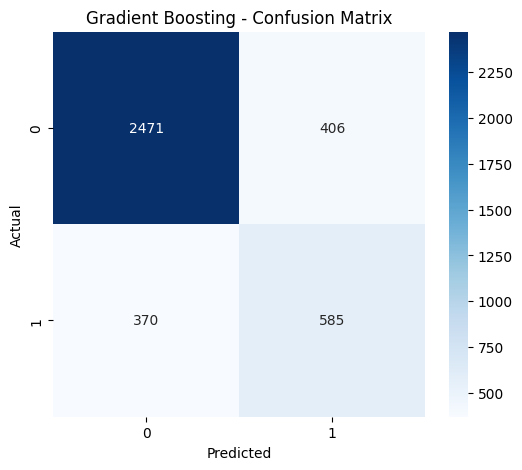

In [137]:


cm = confusion_matrix(y_val, y_pred_final)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Gradient Boosting - Confusion Matrix')

plt.show()

In [138]:
feature_names = preprocessor.get_feature_names_out()

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': final_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    'Importance',
    ascending=False
)

feature_importance.head(20)

,Feature,Importance
0,num__city_development_index,0.405317
154,cat__company_size_Unknown,0.179880
3,num__training_hours,0.057189
145,cat__major_discipline_Unknown,0.056921
1,num__experience,0.045554
10,cat__city_city_103,0.023997
2,num__last_new_job,0.019213
134,cat__education_level_Graduate,0.015931
161,cat__company_type_Unknown,0.013291
4,num__relevent_experience,0.012157


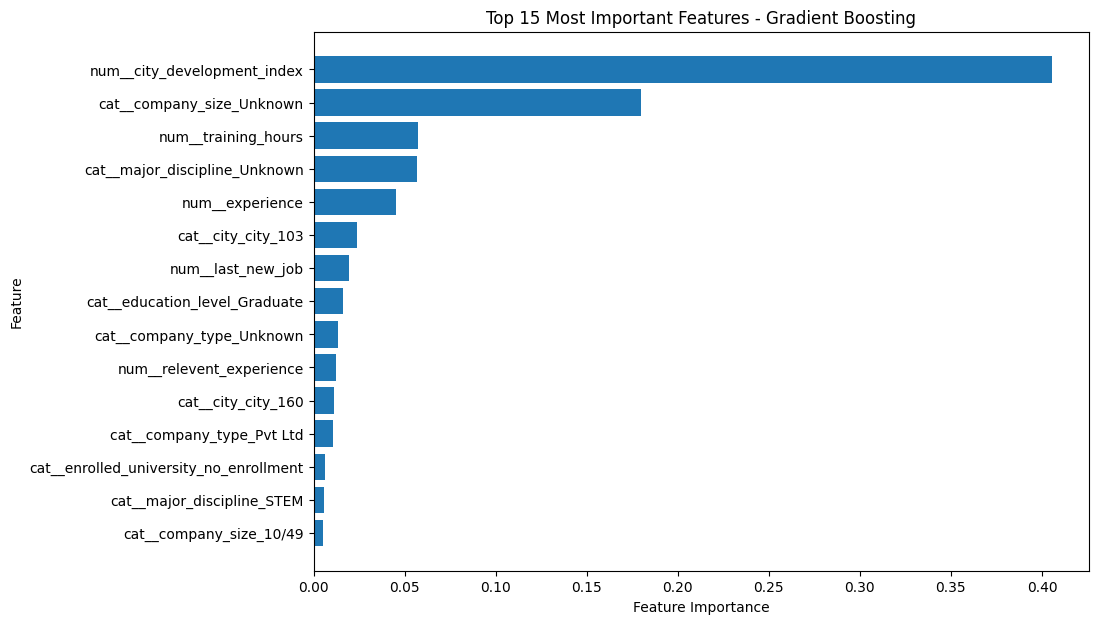

In [139]:
top_features = feature_importance.head(15)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features['Feature'][::-1],
    top_features['Importance'][::-1]
)

plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Top 15 Most Important Features - Gradient Boosting')

plt.show()

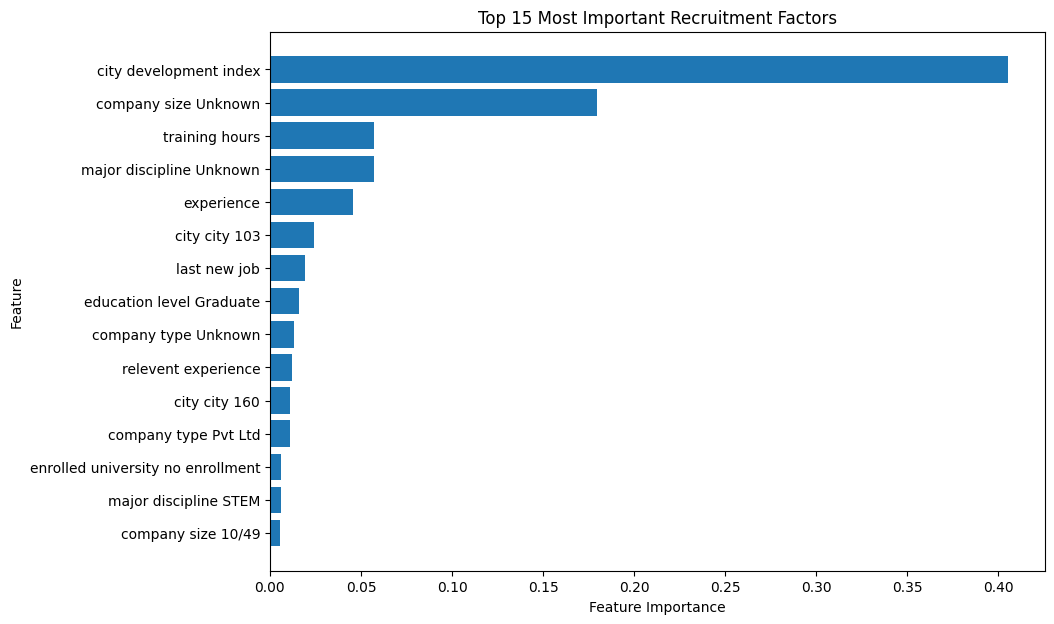

In [140]:
top_features = feature_importance.head(15).copy()

top_features['Feature'] = (
    top_features['Feature']
    .str.replace('num__', '', regex=False)
    .str.replace('cat__', '', regex=False)
    .str.replace('_', ' ', regex=False)
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features['Feature'][::-1],
    top_features['Importance'][::-1]
)

plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Top 15 Most Important Recruitment Factors')

plt.show()

In [141]:
X.columns.tolist()

['city',
 'city_development_index',
 'gender',
 'relevent_experience',
 'enrolled_university',
 'education_level',
 'major_discipline',
 'experience',
 'company_size',
 'company_type',
 'last_new_job',
 'training_hours',
 'experience_level',
 'development_level',
 'gender_missing',
 'major_discipline_missing',
 'company_size_missing',
 'company_type_missing',
 'high_training']

In [142]:
probabilities = final_model.predict_proba(
    X_val_processed
)[:, 1]

ranking = X_val.copy()

ranking['Job_Change_Probability'] = probabilities

top_10 = ranking.sort_values(
    'Job_Change_Probability',
    ascending=False
).head(10)

top_10

,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,experience_level,development_level,gender_missing,major_discipline_missing,company_size_missing,company_type_missing,high_training,Job_Change_Probability
436,city_70,0.698,Male,0,Part time course,Graduate,STEM,4,Unknown,Unknown,2,7,Junior,Medium,0,0,1,1,0,0.927640
3140,city_155,0.556,Male,1,Full time course,Graduate,STEM,1,500-999,Pvt Ltd,0,46,Entry,Low,0,0,0,0,0,0.892378
11149,city_7,0.647,Male,1,Full time course,Masters,STEM,4,Unknown,Unknown,1,13,Junior,Medium,0,0,1,1,0,0.872455
7154,city_7,0.647,Unknown,0,Full time course,Graduate,STEM,15,Unknown,Unknown,2,23,Senior,Medium,1,0,1,1,0,0.838871
1351,city_21,0.624,Female,1,no_enrollment,Graduate,STEM,3,10/49,Pvt Ltd,2,7,Junior,Medium,0,0,0,0,0,0.826842
14803,city_155,0.556,Unknown,1,no_enrollment,Graduate,STEM,16,<10,Early Stage Startup,1,26,Senior,Low,1,0,0,0,0,0.823383
14233,city_21,0.624,Unknown,1,Part time course,Graduate,STEM,3,10/49,Pvt Ltd,2,15,Junior,Medium,1,0,0,0,0,0.823285
11591,city_155,0.556,Male,1,Full time course,Graduate,STEM,6,50-99,Pvt Ltd,1,32,Mid,Low,0,0,0,0,0,0.821118
9083,city_42,0.563,Male,0,Full time course,Graduate,STEM,5,50-99,Pvt Ltd,2,100,Junior,Low,0,0,0,0,1,0.804922
9930,city_21,0.624,Unknown,1,Full time course,Masters,STEM,3,10/49,Pvt Ltd,1,11,Junior,Medium,1,0,0,0,0,0.799149


In [143]:
top_10['Probability_%'] = (
    top_10['Job_Change_Probability'] * 100
)

top_10[['Probability_%']]

,Probability_%
436,92.764024
3140,89.237775
11149,87.245455
7154,83.887080
1351,82.684172
14803,82.338340
14233,82.328544
11591,82.111755
9083,80.492198
9930,79.914863


In [144]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    final_model,
    X_train_processed,
    y_train,
    cv=5,
    scoring='accuracy'
)

print("CV Scores:", cv_scores)
print("Mean Accuracy:", cv_scores.mean())
print("Std:", cv_scores.std())

CV Scores: [0.78538813 0.79934747 0.79184339 0.79347471 0.78597064]
Mean Accuracy: 0.7912048686376604
Std: 0.005159332454135995


In [145]:
import pickle
import os

os.makedirs("models", exist_ok=True)

models = {
    "logistic_regression_model": logistic_model,
    "random_forest_model": rf_model,
    "xgboost_model": xgb_model,
    "gradient_boosting_model": gb_model
}

for name, model in models.items():
    with open(f"models/{name}.pkl", "wb") as file:
        pickle.dump(model, file)

print("All models saved successfully as .pkl")

All models saved successfully as .pkl
